# HAM10000 ResNet Fine-tuning
This notebook demonstrates how to fine-tune a ResNet model on the HAM10000 dataset using the `ResNetFineTuneTrainer` class.

In [1]:
import sys
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / 'python'))

Project directory set to: E:\Admin\Documents\dermascan


In [2]:
# from dataset_manager import DatasetManager
from pipeline.resnet_finetune_train import ResNetFineTuneTrainer

import pandas as pd

In [3]:
# 1. Prepare the Data
train_df = pd.read_csv(proj_dir / "data" / "train_df.csv")
val_df = pd.read_csv(proj_dir / "data" / "val_df.csv")
test_df = pd.read_csv(proj_dir / "data" / "test_df.csv")

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")

Training samples: 5861
Validation samples: 782
Test samples: 1173


In [ ]:
# 2. Configure the Trainer
trainer = ResNetFineTuneTrainer()

# Set up the model (ResNet50, 2 classes: nv vs mel)
trainer.set_model(model_name='resnet18', pretrained=True, input_channels=3)

# Set data loaders
trainer.set_data_loaders(train_df, val_df, test_df, filter_name='rgb', data_path=proj_dir / "data")

# Configure optimizer and scheduler
trainer.configure_optimizer(optimizer_type='adam', lr=1e-4, weight_decay=1e-4)
trainer.configure_scheduler(scheduler_type='reduce_on_plateau', patience=3)

# Set output paths for artifacts
trainer.set_output_paths(
    model_save_dir=str(proj_dir / "python" / "results" / "models"),
    results_csv_path=str(proj_dir / "python" / "results" / "training_results.csv"),
    history_plot_dir=str(proj_dir / "python" / "results" / "plots")
)

In [ ]:
# 3. Train the Model
# Train for a specified number of epochs
trainer.train(epochs=100)

Epoch 1/1
----------
train Loss: 0.4198 Acc: 0.8362
val Loss: 0.3654 Acc: 0.8581
Training complete in 7m 49s
Best val Acc: 0.8581


Evaluation results - F1 (macro): 0.4617, F1 (weighted): 0.7919, AUC: 0.7244, Accuracy: 0.8576, Sensitivity: 0.0000, Specificity: 1.0000


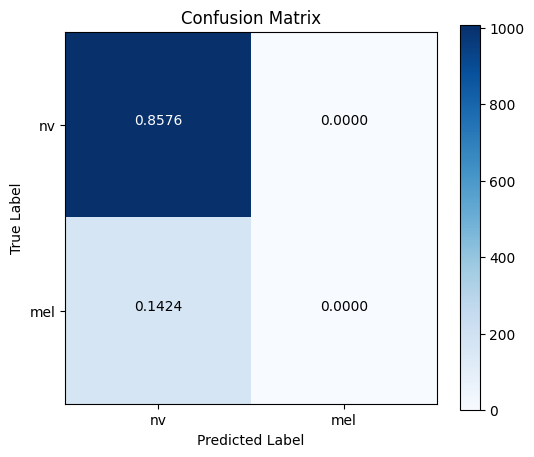

In [6]:
# 4. Evaluate and Save Results
trainer.evaluate()
trainer.save_results_to_csv()